## Laboratory 2: Geometric and Intensity Transformations

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

input_img = './mountains.jpg'

### Problem 1: Implementation of Geometric Transformations

1. Scaling

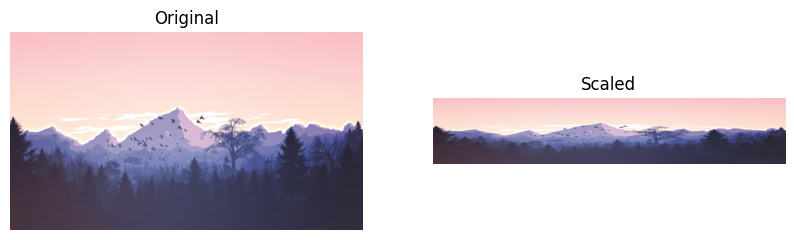

In [ ]:
dx = float(input("Horizontal scaling factor: "))
dy = float(input("Vertical scaling factor: "))

img = cv2.imread(input_img)

rows, cols = img.shape[:2]

mat = np.float32([
    [dx, 0, 0],
    [0, dy, 0]
])

new_cols = int(cols * dx)
new_rows = int(rows * dy)

scaled = cv2.warpAffine(img, mat, (new_cols, new_rows))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(scaled, cv2.COLOR_BGR2RGB))
plt.title('Scaled')
plt.axis('off')

plt.show()

2. Rotation
• 45 degrees
• 60 degrees

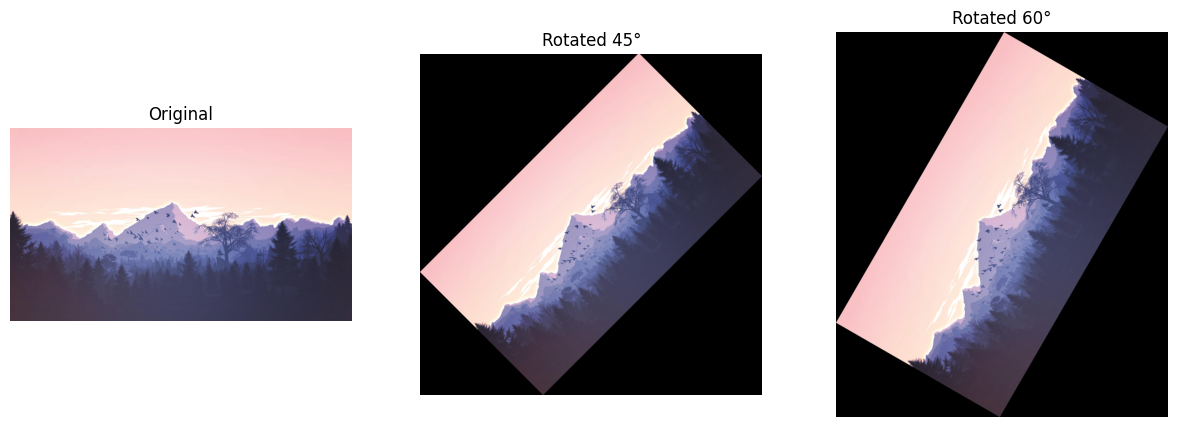

In [3]:
def rotate_image(image, angle):
    rows, cols = image.shape[:2]
    
    M = cv2.getRotationMatrix2D((cols/2, rows/2), angle, 1)
    
    cos = abs(M[0, 0])
    sin = abs(M[0, 1])
    
    new_cols = int((rows * sin) + (cols * cos))
    new_rows = int((rows * cos) + (cols * sin))
    
    M[0, 2] += (new_cols / 2) - cols/2
    M[1, 2] += (new_rows / 2) - rows/2
    
    rotated = cv2.warpAffine(image, M, (new_cols, new_rows))
    
    return rotated

rot_45 = rotate_image(img, 45)
rot_60 = rotate_image(img, 60)

fig, ax = plt.subplots(1,3, figsize=(15,5))

ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(cv2.cvtColor(rot_45, cv2.COLOR_BGR2RGB))
ax[1].set_title("Rotated 45°")
ax[1].axis("off")

ax[2].imshow(cv2.cvtColor(rot_60, cv2.COLOR_BGR2RGB))
ax[2].set_title("Rotated 60°")
ax[2].axis("off")

plt.show()

### Problem 2: Intensity Transformations

1. Photographic Negative Transformation

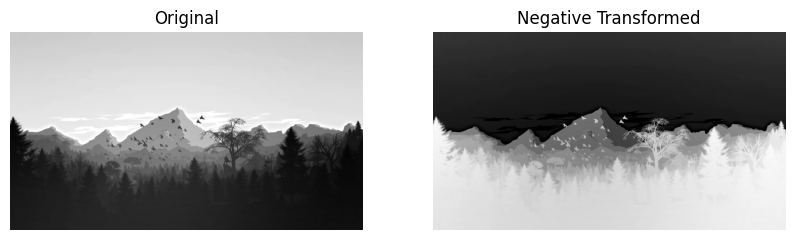

In [4]:
img_gray=cv2.imread(input_img,0)

negative_img=255-img_gray

fig,ax=plt.subplots(1,2,figsize=(10,5))
ax[0].imshow(img_gray,cmap='gray')
ax[0].set_title('Original')
ax[0].axis('off')

ax[1].imshow(negative_img,cmap='gray')
ax[1].set_title('Negative Transformed')
ax[1].axis('off')

plt.show()

2. Gamma Transformation

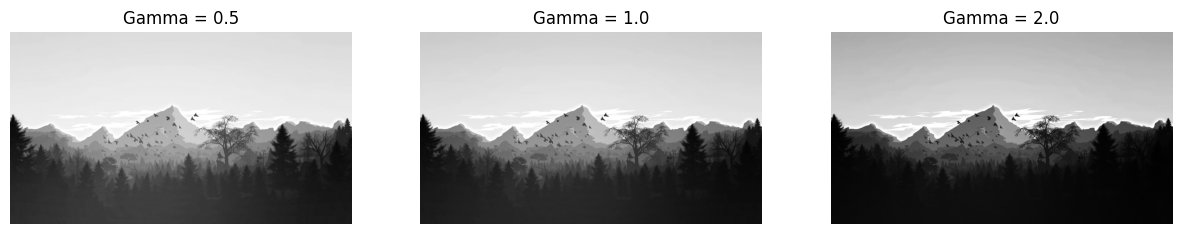

In [5]:
img=cv2.imread(input_img,0)
img_norm = img / 255.0

gamma_values = [0.5, 1.0, 2.0]

plt.figure(figsize=(15,5))

for i, gamma in enumerate(gamma_values):
    
    corrected = np.power(img_norm, gamma)
    
    corrected = np.uint8(corrected * 255)
    
    plt.subplot(1,3,i+1)
    plt.imshow(corrected, cmap='gray')
    plt.title(f'Gamma = {gamma}')
    plt.axis('off')

plt.show()

3. Logarithmic Transformation

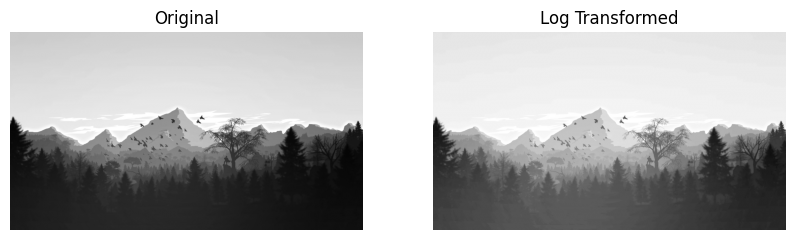

In [6]:
img=cv2.imread(input_img,0)

img_float = img.astype(np.float32)

c = 255 / np.log(1 + np.max(img_float))
log_transformed = c * np.log(1 + img_float)

log_transformed = np.uint8(log_transformed)

fig, ax = plt.subplots(1,2, figsize=(10,5))

ax[0].imshow(img, cmap='gray')
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(log_transformed, cmap='gray')
ax[1].set_title("Log Transformed")
ax[1].axis("off")

plt.show()

4. Contrast Stretching (changing e)

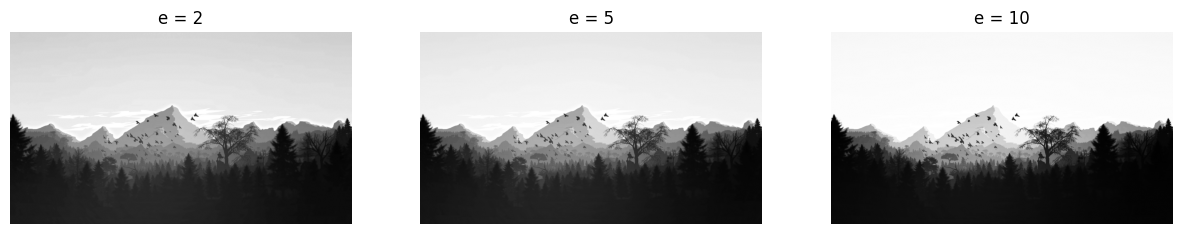

In [7]:
img = cv2.imread(input_img, 0)

img_norm = img / 255.0

m = 0.5
e_values = [2, 5, 10]

plt.figure(figsize=(15,5))

for i, e in enumerate(e_values):
    
    stretched = 1 / (1 + np.exp(-e * (img_norm - m)))
    
    stretched = np.uint8(stretched * 255)
    
    plt.subplot(1,3,i+1)
    plt.imshow(stretched, cmap='gray')
    plt.title(f'e = {e}')
    plt.axis('off')

plt.show()

5. Contrast Stretching (changing m)

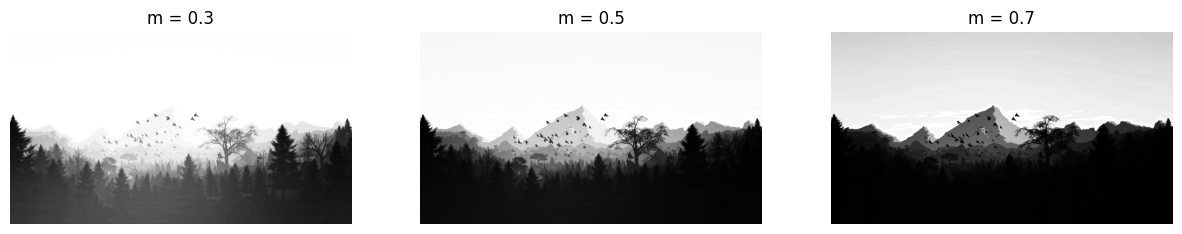

In [8]:
img = cv2.imread(input_img, 0)

img_norm = img / 255.0

k = 10
m_values = [0.3, 0.5, 0.7]

plt.figure(figsize=(15,5))

for i, m in enumerate(m_values):
    
    stretched = 1 / (1 + np.exp(-k * (img_norm - m)))
    
    stretched = np.uint8(stretched * 255)
    
    plt.subplot(1,3,i+1)
    plt.imshow(stretched, cmap='gray')
    plt.title(f'm = {m}')
    plt.axis('off')

plt.show()

### Problem 3: Bit Plane Slicing

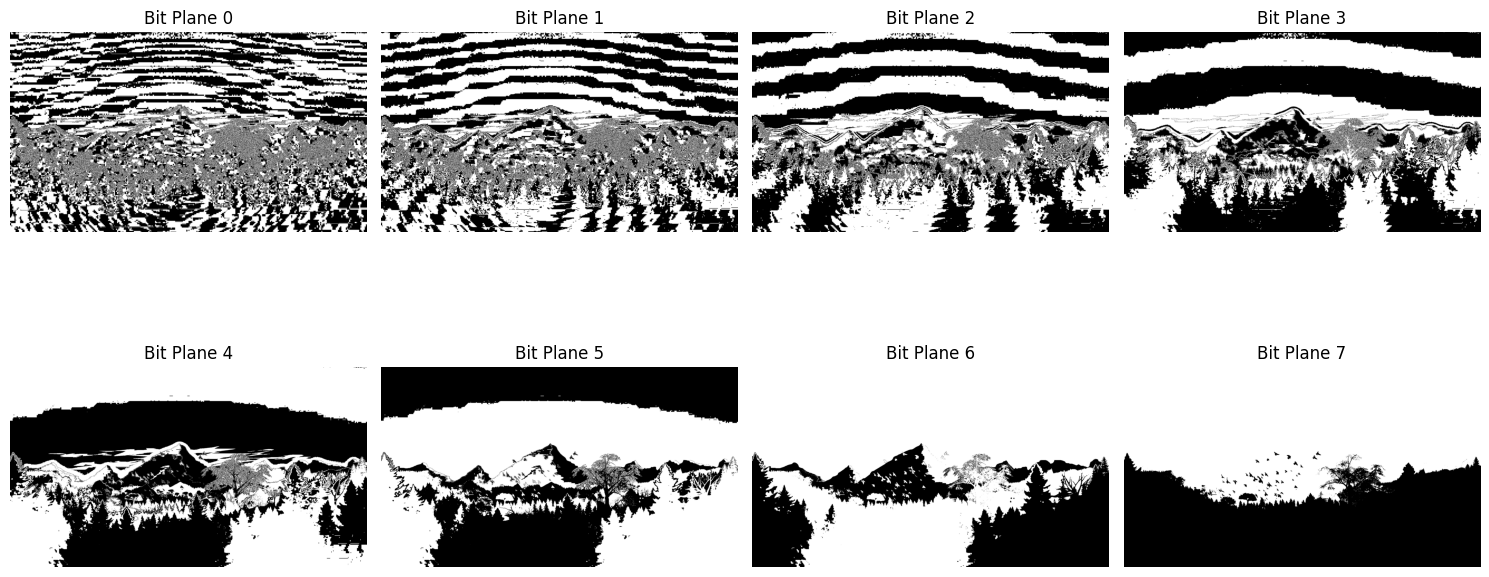

In [9]:
img = cv2.imread(input_img, 0)

plt.figure(figsize=(15,8))

for i in range(8):
    bit_plane = (img >> i) & 1
    bit_plane = bit_plane * 255
    
    plt.subplot(2,4,i+1)
    plt.imshow(bit_plane, cmap='gray')
    plt.title(f'Bit Plane {i}')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Problem 4: Contrast Enhancement and Histogram

1. Linear Contrast Stretching

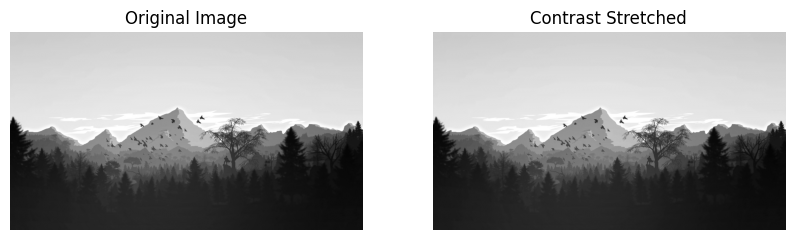

In [10]:
img = cv2.imread(input_img, 0)

r_min = np.min(img)
r_max = np.max(img)

stretched = (img - r_min) * (255 / (r_max - r_min))
stretched = np.uint8(stretched)

fig, ax = plt.subplots(1,2, figsize=(10,5))

ax[0].imshow(img, cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(stretched, cmap='gray')
ax[1].set_title("Contrast Stretched")
ax[1].axis("off")

plt.show()

2. Non-linear Contrast stretching

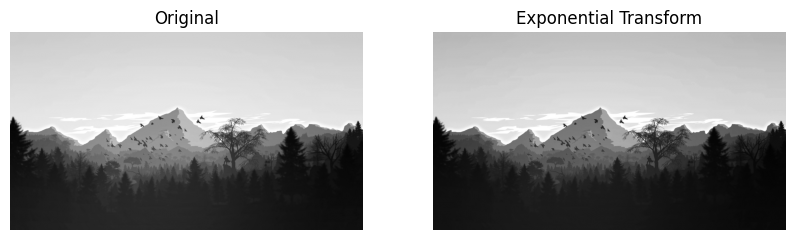

In [11]:
img=cv2.imread(input_img,0)
img_norm = img / 255.0

exp_trans = np.exp(img_norm) - 1

# Normalize
exp_trans = exp_trans / np.max(exp_trans)
exp_trans = np.uint8(exp_trans * 255)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(exp_trans, cmap='gray')
plt.title("Exponential Transform")
plt.axis("off")

plt.show()

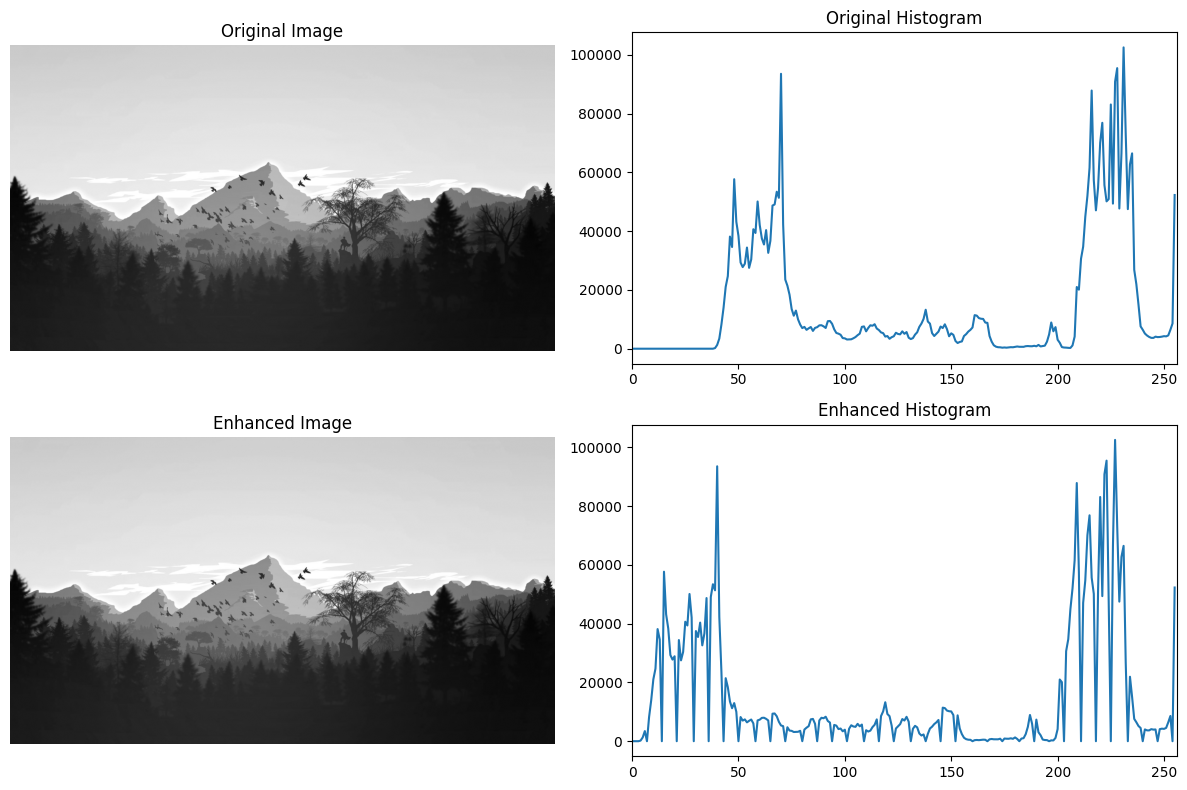

In [12]:
# Read grayscale image
img = cv2.imread(input_img, 0)

# Linear contrast stretching
r_min = np.min(img)
r_max = np.max(img)
enhanced = (img - r_min) * (255 / (r_max - r_min))
enhanced = np.uint8(enhanced)

# Compute histograms
hist_original = cv2.calcHist([img], [0], None, [256], [0,256])
hist_enhanced = cv2.calcHist([enhanced], [0], None, [256], [0,256])

# Plot
plt.figure(figsize=(12,8))

# Original Image
plt.subplot(2,2,1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

# Original Histogram
plt.subplot(2,2,2)
plt.plot(hist_original)
plt.title("Original Histogram")
plt.xlim([0,256])

# Enhanced Image
plt.subplot(2,2,3)
plt.imshow(enhanced, cmap='gray')
plt.title("Enhanced Image")
plt.axis("off")

# Enhanced Histogram
plt.subplot(2,2,4)
plt.plot(hist_enhanced)
plt.title("Enhanced Histogram")
plt.xlim([0,256])

plt.tight_layout()
plt.show()

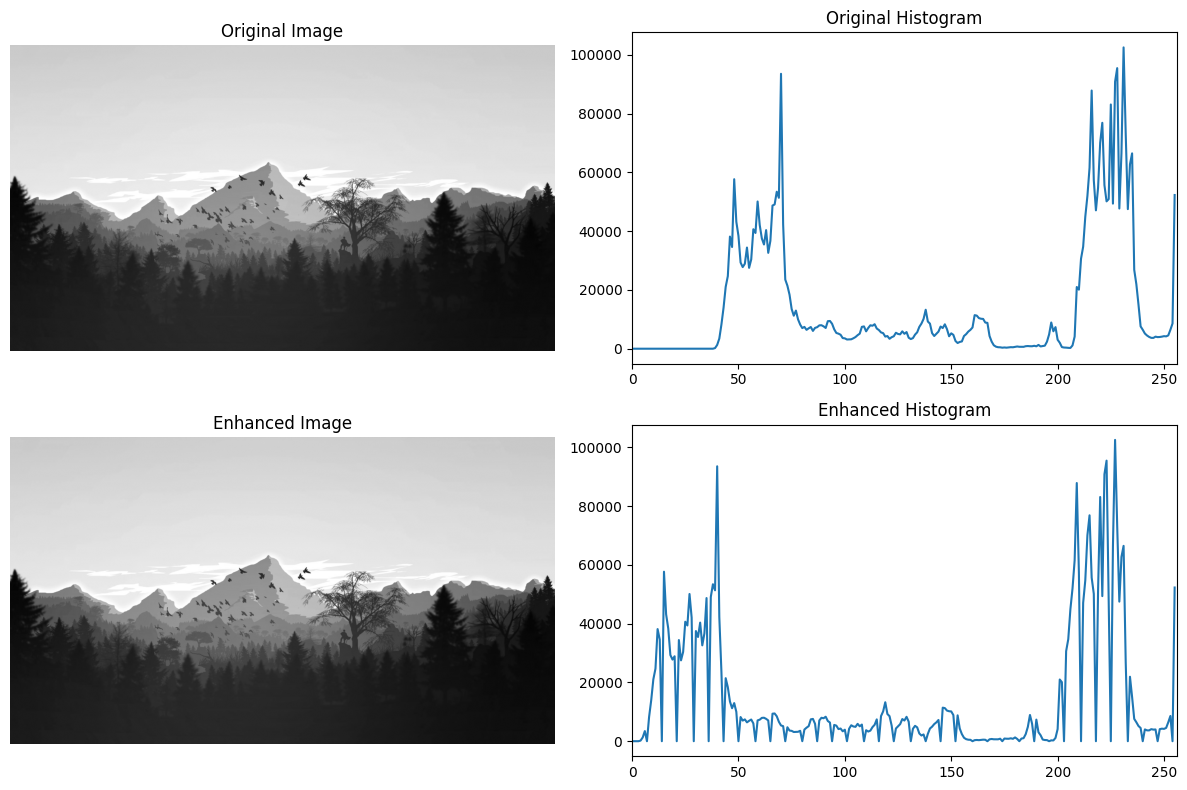

In [13]:
img = cv2.imread(input_img, 0)

# Linear contrast stretching
r_min = np.min(img)
r_max = np.max(img)
enhanced = (img - r_min) * (255 / (r_max - r_min))
enhanced = np.uint8(enhanced)

# Compute histograms
hist_original = cv2.calcHist([img], [0], None, [256], [0,256])
hist_enhanced = cv2.calcHist([enhanced], [0], None, [256], [0,256])

# Plot
plt.figure(figsize=(12,8))

# Original Image
plt.subplot(2,2,1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

# Original Histogram
plt.subplot(2,2,2)
plt.plot(hist_original)
plt.title("Original Histogram")
plt.xlim([0,256])

# Enhanced Image
plt.subplot(2,2,3)
plt.imshow(enhanced, cmap='gray')
plt.title("Enhanced Image")
plt.axis("off")

# Enhanced Histogram
plt.subplot(2,2,4)
plt.plot(hist_enhanced)
plt.title("Enhanced Histogram")
plt.xlim([0,256])

plt.tight_layout()
plt.show()

5. Histogram Equalization

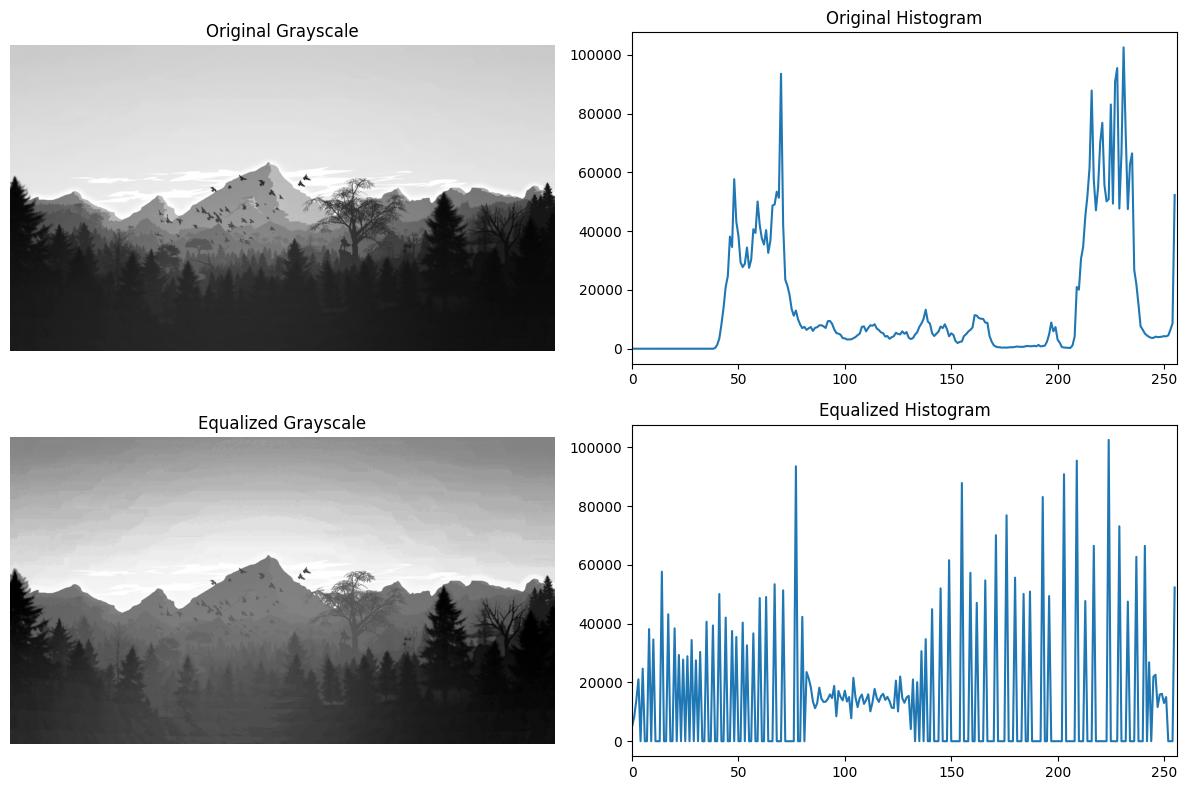

In [14]:
img_gray = cv2.imread(input_img, 0)

equalized_gray = cv2.equalizeHist(img_gray)

hist_original = cv2.calcHist([img_gray],[0],None,[256],[0,256])
hist_equalized = cv2.calcHist([equalized_gray],[0],None,[256],[0,256])

plt.figure(figsize=(12,8))

plt.subplot(2,2,1)
plt.imshow(img_gray, cmap='gray')
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(2,2,2)
plt.plot(hist_original)
plt.title("Original Histogram")
plt.xlim([0,256])

plt.subplot(2,2,3)
plt.imshow(equalized_gray, cmap='gray')
plt.title("Equalized Grayscale")
plt.axis("off")

plt.subplot(2,2,4)
plt.plot(hist_equalized)
plt.title("Equalized Histogram")
plt.xlim([0,256])

plt.tight_layout()
plt.show()

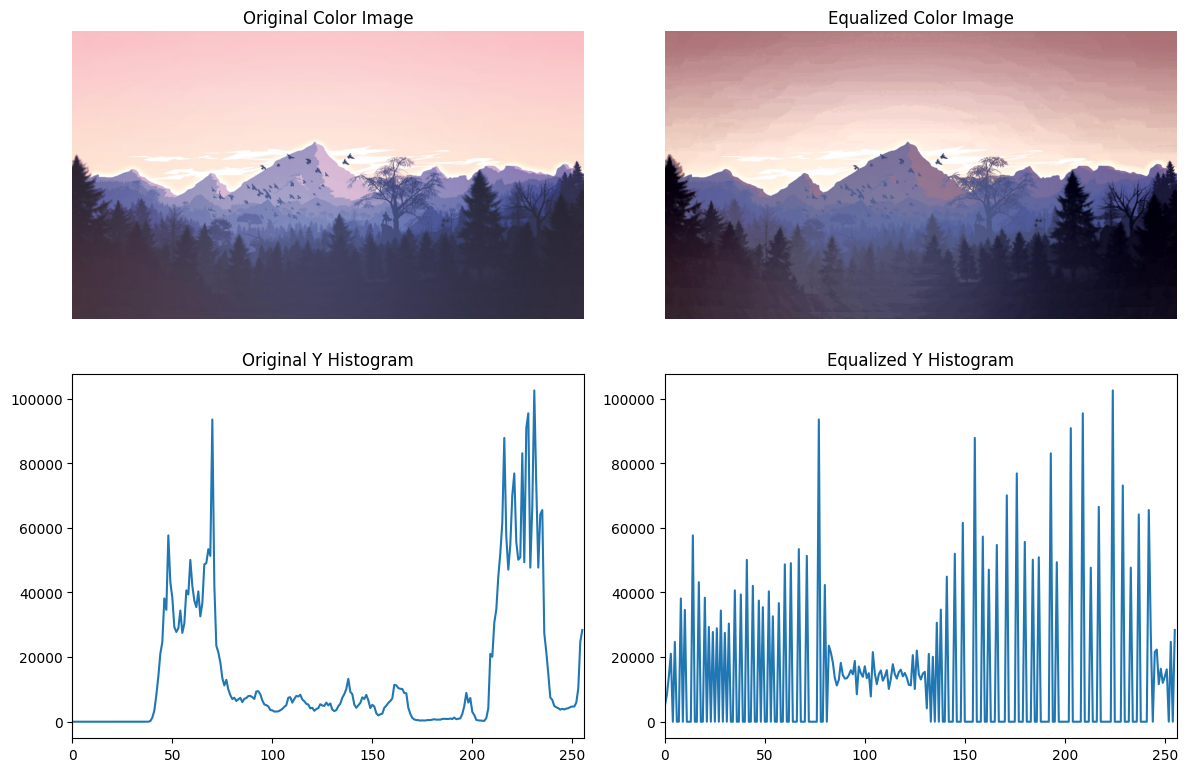

In [15]:
img_color = cv2.imread(input_img)

ycrcb = cv2.cvtColor(img_color, cv2.COLOR_BGR2YCrCb)

Y_original = ycrcb[:,:,0].copy()

ycrcb[:,:,0] = cv2.equalizeHist(ycrcb[:,:,0])

Y_equalized = ycrcb[:,:,0]

equalized_color = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)
original_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
equalized_rgb = cv2.cvtColor(equalized_color, cv2.COLOR_BGR2RGB)

hist_original = cv2.calcHist([Y_original],[0],None,[256],[0,256])
hist_equalized = cv2.calcHist([Y_equalized],[0],None,[256],[0,256])

plt.figure(figsize=(12,8))

plt.subplot(2,2,1)
plt.imshow(original_rgb)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(equalized_rgb)
plt.title("Equalized Color Image")
plt.axis("off")

plt.subplot(2,2,3)
plt.plot(hist_original)
plt.title("Original Y Histogram")
plt.xlim([0,256])

plt.subplot(2,2,4)
plt.plot(hist_equalized)
plt.title("Equalized Y Histogram")
plt.xlim([0,256])

plt.tight_layout()
plt.show()